# Train


In [27]:
%pip install torch torchvision scikit-learn matplotlib Pillow

Note: you may need to restart the kernel to use updated packages.


## Notebook settings

In [28]:
from pathlib import Path
from datetime import datetime

random_state = 42
data_loc = Path("data_nouveau_split")
dossier_train = data_loc / "train"
dossier_val = data_loc / "val"
dossier_test = data_loc / "test"
epochs_phase1 = 10
epochs_phase2 = 5

## CPU/GPU

In [29]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print('Using gpu: %s ' % torch.cuda.is_available())

Using gpu: False 


## Prepare images

The images are resized to 224 × 224, and the normalization expected by the ImageNet weights is applied. (Source: EfficientNetB0 documentation / v2 transformation)

In [30]:
from torchvision.transforms import v2

transform = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224), antialias=True),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

## Loading datasets

ImageFolder reads images in RGB format and assigns a class to each subfolder (source: ImageFolder documentation)

In [31]:
from torchvision.datasets import ImageFolder

train_data = ImageFolder(dossier_train, transform=transform)
val_data = ImageFolder(dossier_val, transform=transform)
test_data = ImageFolder(dossier_test, transform=transform)

classes = ["NORMAL", "PNEUMONIA"]

#verif
for dataset in (train_data, val_data, test_data):
    print(dataset.class_to_idx == {"NORMAL": 0, "PNEUMONIA": 1})


True
True
True


## Creating batches


In [32]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=False)
test_loader = DataLoader(test_data, batch_size=32, shuffle=False)

## Model

In [33]:
from torch import nn
import torchvision.models as models

weights = models.EfficientNet_B0_Weights.DEFAULT # poids pré entraînés sur imageNet

model = models.efficientnet_b0(weights=weights)

model.classifier = nn.Sequential( #nouvelle tete
    nn.Linear(1280, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 1),
)

model = model.to(device)

for parameter in model.features.parameters():
    parameter.requires_grad = False # On gèle les poids du modèle pré-entraîné

## Loss

Using BCEWithLogitsLoss, as it combines sigmoid and binary loss in a numerically stable way.

In [34]:
criterion = nn.BCEWithLogitsLoss()

def classification_loss(model, logits, labels):
    loss = criterion(logits, labels)
    return loss + 1e-4 * model.classifier[0].weight.square().sum()

## Evaluation

In [35]:
def test_CNN(modele, batchs_test, critere):  

    modele.eval()  
    test_loss = 0  
    correct = 0  

    with torch.no_grad():  #désactiver le calcul des gradients 

        for data, target in batchs_test : 
            data = data.to(device)  
            target = target.to(device) 

            output = modele(data).flatten()
            test_loss += critere(output, target.float()).item()*len(target) 

            pred = torch.sigmoid(output) >= 0.5  #prédit pneumonia si la probabilité atteint 0,5
            correct += pred.eq(target).sum()  

        test_loss = test_loss /len(batchs_test.dataset) 
        print('\nVal set: Avg. loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(test_loss, correct, len(batchs_test.dataset), 100. * correct / len(batchs_test.dataset)))
        return test_loss

## Train

In [36]:
from tqdm.auto import tqdm #viauslalisation de la progression

def train_CNN(model, trainloader, val_loader, loss_fn, n_epochs, optimizer):

    meilleure_loss = test_CNN(model, val_loader, loss_fn)
    torch.save(model.state_dict(), "meilleur_modele.pth")

    for epoch in tqdm(range(n_epochs), desc="Progression totale"):

        model.train()
        model.features.eval()

        running_loss = 0.0
        for batch_idx, (inputs, targets) in enumerate(tqdm(trainloader, desc=f"Époque {epoch + 1}/{n_epochs}", leave=False)):

            optimizer.zero_grad()
            inputs = inputs.to(device)
            targets = targets.to(device) 
            outputs = model(inputs).flatten()

            loss = loss_fn(outputs, targets.float())
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(targets)

        val_loss = test_CNN(model, val_loader, loss_fn)

        if val_loss < meilleure_loss:
            meilleure_loss = val_loss
            torch.save(model.state_dict(), "meilleur_modele.pth")

    print(f'epoch : {epoch + 1} loss: {running_loss / len(trainloader.dataset):.3f}')
    model.load_state_dict(torch.load("meilleur_modele.pth", map_location=device, weights_only=True))

## Train the head

In [37]:
optimizer = torch.optim.Adam(model.classifier.parameters(),lr=0.001)
train_CNN(model,train_loader,val_loader,criterion,epochs_phase1,optimizer)


Val set: Avg. loss: 0.6949, Accuracy: 410/874 (47%)



Progression totale:   0%|          | 0/10 [00:00<?, ?it/s]

Époque 1/10:   0%|          | 0/128 [00:00<?, ?it/s]


Val set: Avg. loss: 0.1370, Accuracy: 829/874 (95%)



Époque 2/10:   0%|          | 0/128 [00:00<?, ?it/s]

...


Val set: Avg. loss: 0.0966, Accuracy: 844/874 (97%)



Époque 9/10:   0%|          | 0/128 [00:00<?, ?it/s]


Val set: Avg. loss: 0.0933, Accuracy: 846/874 (97%)



Époque 10/10:   0%|          | 0/128 [00:00<?, ?it/s]


Val set: Avg. loss: 0.1156, Accuracy: 841/874 (96%)

epoch : 10 loss: 0.077


##  Adjust last blocs

We unfreeze the final feature blocks and reduce the learning rate.

In [38]:
for parameter in model.features[-2:].parameters():
    parameter.requires_grad = True

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()),lr=0.00001)

train_CNN(model, train_loader, val_loader, criterion, epochs_phase2, optimizer)


Val set: Avg. loss: 0.0901, Accuracy: 844/874 (97%)



Progression totale:   0%|          | 0/5 [00:00<?, ?it/s]

Époque 1/5:   0%|          | 0/128 [00:00<?, ?it/s]


Val set: Avg. loss: 0.0898, Accuracy: 845/874 (97%)



Époque 2/5:   0%|          | 0/128 [00:00<?, ?it/s]

...


Val set: Avg. loss: 0.0865, Accuracy: 848/874 (97%)



Époque 4/5:   0%|          | 0/128 [00:00<?, ?it/s]


Val set: Avg. loss: 0.0843, Accuracy: 848/874 (97%)



Époque 5/5:   0%|          | 0/128 [00:00<?, ?it/s]


Val set: Avg. loss: 0.0865, Accuracy: 848/874 (97%)

epoch : 5 loss: 0.061


## Compare thresholds

Comparison of thresholds from 0.3 to 0.8

Loss : 0.0843
AUC : 0.9944

Seuil : 0.3
              precision    recall  f1-score   support

      NORMAL     0.9309    0.9140    0.9224       221
   PNEUMONIA     0.9711    0.9770    0.9740       653

    accuracy                         0.9611       874
   macro avg     0.9510    0.9455    0.9482       874
weighted avg     0.9609    0.9611    0.9610       874


Seuil : 0.4
              precision    recall  f1-score   support

      NORMAL     0.9292    0.9502    0.9396       221
   PNEUMONIA     0.9830    0.9755    0.9792       653

    accuracy                         0.9691       874
   macro avg     0.9561    0.9629    0.9594       874
weighted avg     0.9694    0.9691    0.9692       874


Seuil : 0.5
              precision    recall  f1-score   support

      NORMAL     0.9221    0.9638    0.9425       221
   PNEUMONIA     0.9876    0.9724    0.9799       653

    accuracy                         0.9703       874
   macro avg     0.9548    0.9681    0.9612       874
weighted

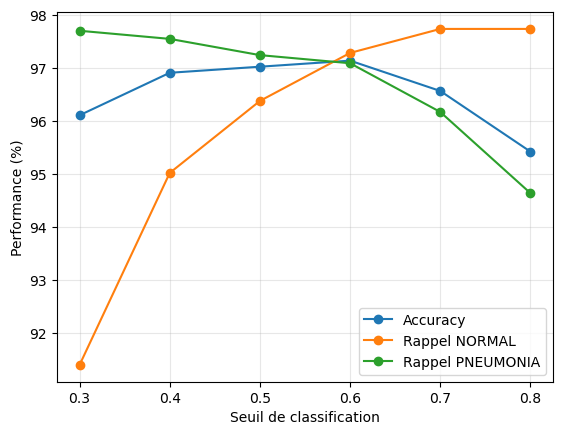

In [46]:
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, recall_score
import matplotlib.pyplot as plt

def evaluate(modele, batchs_test, critere, seuils=(0.3, 0.4, 0.5, 0.6, 0.7, 0.8)):
    modele.eval()
    test_loss = 0
    labels = []
    probabilites = []

#collecte des labels et probabilités
    with torch.no_grad():
        for data, target in batchs_test:
            data = data.to(device)
            target = target.to(device)

            output = modele(data).flatten()
            test_loss += critere(output, target.float()).item() * len(target)

            labels.extend(target.cpu().tolist())
            probabilites.extend(torch.sigmoid(output).cpu().tolist())

#loss et AUC moyenne sur l'ensemble du test
    test_loss = test_loss / len(batchs_test.dataset)
    print(f"Loss : {test_loss:.4f}")
    print(f"AUC : {roc_auc_score(labels, probabilites):.4f}")

#affichage des metriques dependant du seuil
    for seuil in seuils:
        pred = [int(p >= seuil) for p in probabilites]
        print(f"\nSeuil : {seuil}")
        print(classification_report(labels, pred, labels=[0, 1], target_names=["NORMAL", "PNEUMONIA"], digits=4, zero_division=0))

    for nom, metrique in [
        ("Accuracy", accuracy_score),
        ("Rappel NORMAL", lambda y, p: recall_score(y, p, pos_label=0)),
        ("Rappel PNEUMONIA", lambda y, p: recall_score(y, p, pos_label=1))
    ]:
        valeurs = [100 * metrique(labels, [int(p >= s) for p in probabilites]) for s in seuils]
        plt.plot(seuils, valeurs, marker="o", label=nom)

    plt.xlabel("Seuil de classification")
    plt.ylabel("Performance (%)")
    plt.xticks(seuils)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

evaluate(model, val_loader, criterion)

## Final evaluation on test set

Loss : 0.1030
AUC : 0.9913

Seuil : 0.6
              precision    recall  f1-score   support

      NORMAL     0.9264    0.9304    0.9284       230
   PNEUMONIA     0.9751    0.9736    0.9743       643

    accuracy                         0.9622       873
   macro avg     0.9507    0.9520    0.9514       873
weighted avg     0.9623    0.9622    0.9622       873



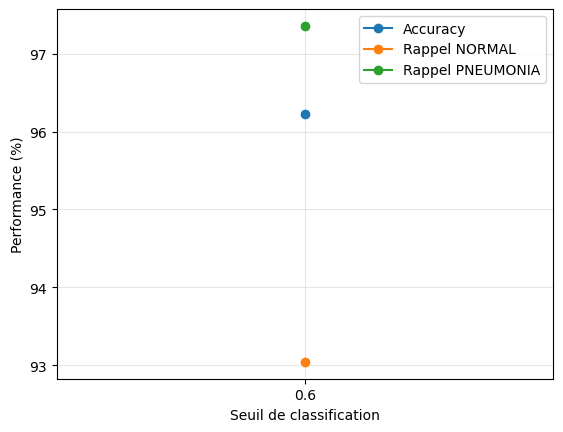

In [47]:
evaluate(model, test_loader, criterion, seuils=[0.6])